In [14]:
import mrcfile
import matplotlib.pyplot as plt
from scipy import ndimage

AuNPs were pickes using ```findbeads3d -i 20240621_15F1Fab-AuNP_9_full_rec_BP.mrc -si 1.5 -ou test.mod -a -48,48 -thresh 0.8```

and then averages using ```for a in  7 8 9; do cd 20240621_15F1Fab-AuNP_${a}/*/; boxstartend -i 20240621_15F1Fab-AuNP_${a}_full_rec_BP.mrc  -m test.mod -ou box.mrc -v 14,14,14; cd ../../; done```

In [6]:
with mrcfile.open("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_7/patch_tracking/box.mrc") as box:
    av1 = box.data[-14:,:,:].copy()
with mrcfile.open("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_8/patch_tracking/box.mrc") as box:
    av2 = box.data[-14:,:,:].copy()
with mrcfile.open("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/20240621_15F1Fab-AuNP/20240621_15F1Fab-AuNP_9/patch_tracking/box.mrc") as box:
    av3 = box.data[-14:,:,:].copy()

In [7]:
av = av1 + av2 + av3

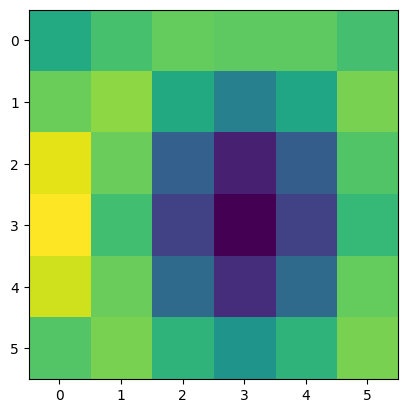

In [40]:
plt.imshow(av[7,4:10,4:10]+av[6,4:10,4:10])

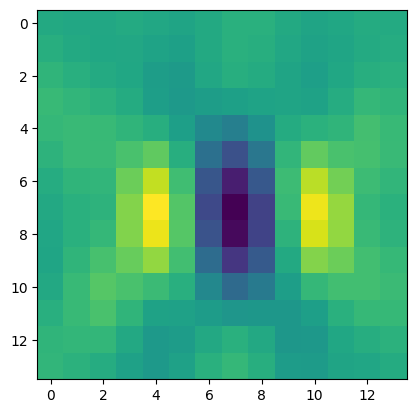

In [17]:
plt.imshow(av[:,7,:]+av[:,6,:])

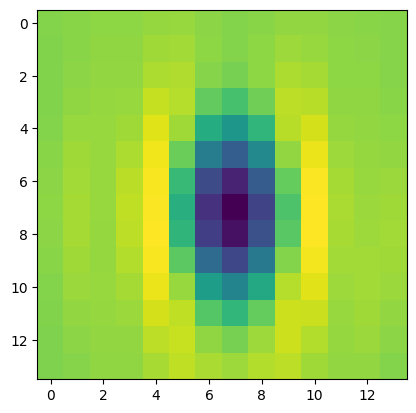

In [18]:
plt.imshow(av[:,:,7]+av[:,:,6])

In [39]:
6.5-np.array(ndimage.center_of_mass(av[4:10,4:10,4:10]))

array([3.55867361, 2.23838206, 0.2388313 ])

In [26]:
import torch
from torch_fourier_shift import fourier_shift_image_3d
import numpy as np

In [22]:
avt = torch.tensor(av, dtype=torch.float32)

In [41]:
shifted_image = fourier_shift_image_3d(image=avt, shifts=torch.tensor([-0.5,-0.5,-0.5]))

In [45]:
shifted_imagec = shifted_image[1:-1,1:-1,1:-1]
shifted_imagec.shape

torch.Size([12, 12, 12])

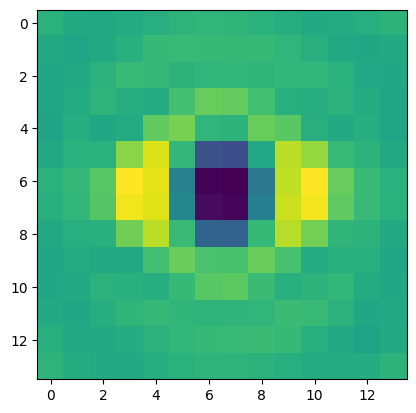

In [42]:
plt.imshow(shifted_image[7]+shifted_image[6])

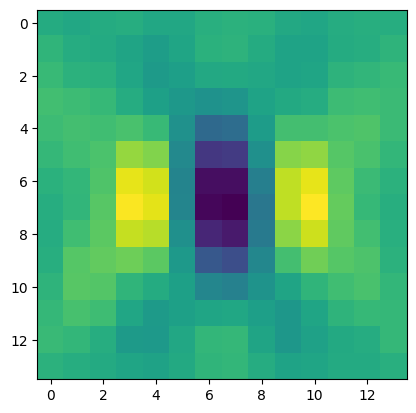

In [43]:
plt.imshow(shifted_image[:,7,:]+shifted_image[:,6,:])

In [47]:
with mrcfile.new("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/temaplte.mrc",overwrite=True) as template:
    template.set_data(shifted_imagec.numpy())


In [71]:
from ttmask.box_setup import box_setup
sphere_radius = 6

# establish our coordinate system and empty mask
coordinates_centered, mask = box_setup(12)

#determine distances of each pixel to the center
distance_to_center = np.linalg.norm(coordinates_centered, axis=-1)

# set up criteria for which pixels are inside the sphere and modify values to 1.
inside_sphere = distance_to_center < (sphere_radius / 1)
mask[inside_sphere] = 1

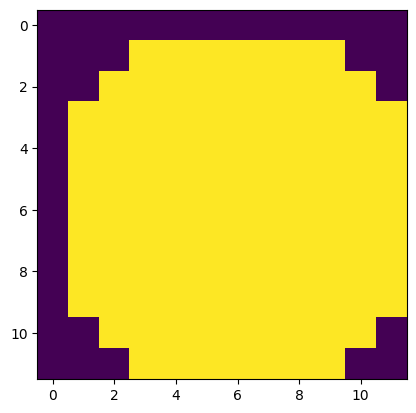

In [72]:
plt.imshow(mask[7]+mask[6])

In [67]:
shifted_mask = fourier_shift_image_3d(image=torch.tensor(mask), shifts=torch.tensor([-0.5,-0.5,-0.5]))

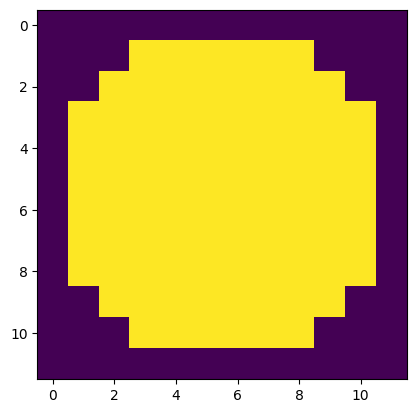

In [68]:
shifted_mask = shifted_mask.numpy()
shifted_mask = shifted_mask > 0.5
shifted_mask = shifted_mask.astype(np.uint8)
plt.imshow(shifted_mask[7]+shifted_mask[6])

In [69]:
mrcfile.write("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/AuNP_tomograms/mask.mrc", shifted_mask, voxel_size=1.0, overwrite=True)

In [70]:
with mrcfile.open("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/20231026_HippAu_14/fiducial_tracking/20231026_HippAu_14_full_rec_BP_flat.mrc") as rec:
    rec_data = rec.data * -1.0
    mrcfile.write("/scratch/pompeii/elferich/gouaux_tomo/ProcessingCJS/tomograms/20231026_HippAu_14/fiducial_tracking/inv.mrc", rec_data, voxel_size=10.0, overwrite=True)